# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Kavan W., Michelle J., Max G."

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

**ANSWER**

- We plan to create histograms to describe our input variables. We could also use a scatterplot and a heatmap to show the relationship between the input and the outcome variables. Also, we plan to standardize all variables to ensure that scale does not impact the models performance.

- We will use fitted scaler to standardize the training and validation set in order to prevent data leakage. Additionally, we will fit our scaler only on the training folds during cross validation.

- We are going to do a regression model because compression strength is a continuous outcome. Our cost function is going to be mean squared error. Our output layer will have one neuron with a linear activation.

- We will use 5-fold cross validation to assess our model's performance. We will measure RMSE and R^2 across each fold. 5-fold cross validation divides into 5 folds, then trains on 4 before using the 5th for testing/validation. It will then average (mean) the performance results of the 5 folds. This makes the evaluation less dependent on a single train validation split. We will use the same folds for all of our variables to ensure a fair comparison.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [1]:
import pandas as pd
file_path = 'Concrete_Data.xls'
df = pd.read_excel(file_path)
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [ ]:
# column headers are not callable
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [ ]:
# clean column names to make them more callable 
df_clean_cols = df.copy()

df_clean_cols.columns =  ["cement", "slag", "fly_ash", "water", "superplasticizer",
              "coarse_agg", "fine_agg", "age", "strength"]

df_clean_cols.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [18]:
# check for missing values
df_clean_cols.isna().sum()

cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age                 0
strength            0
dtype: int64

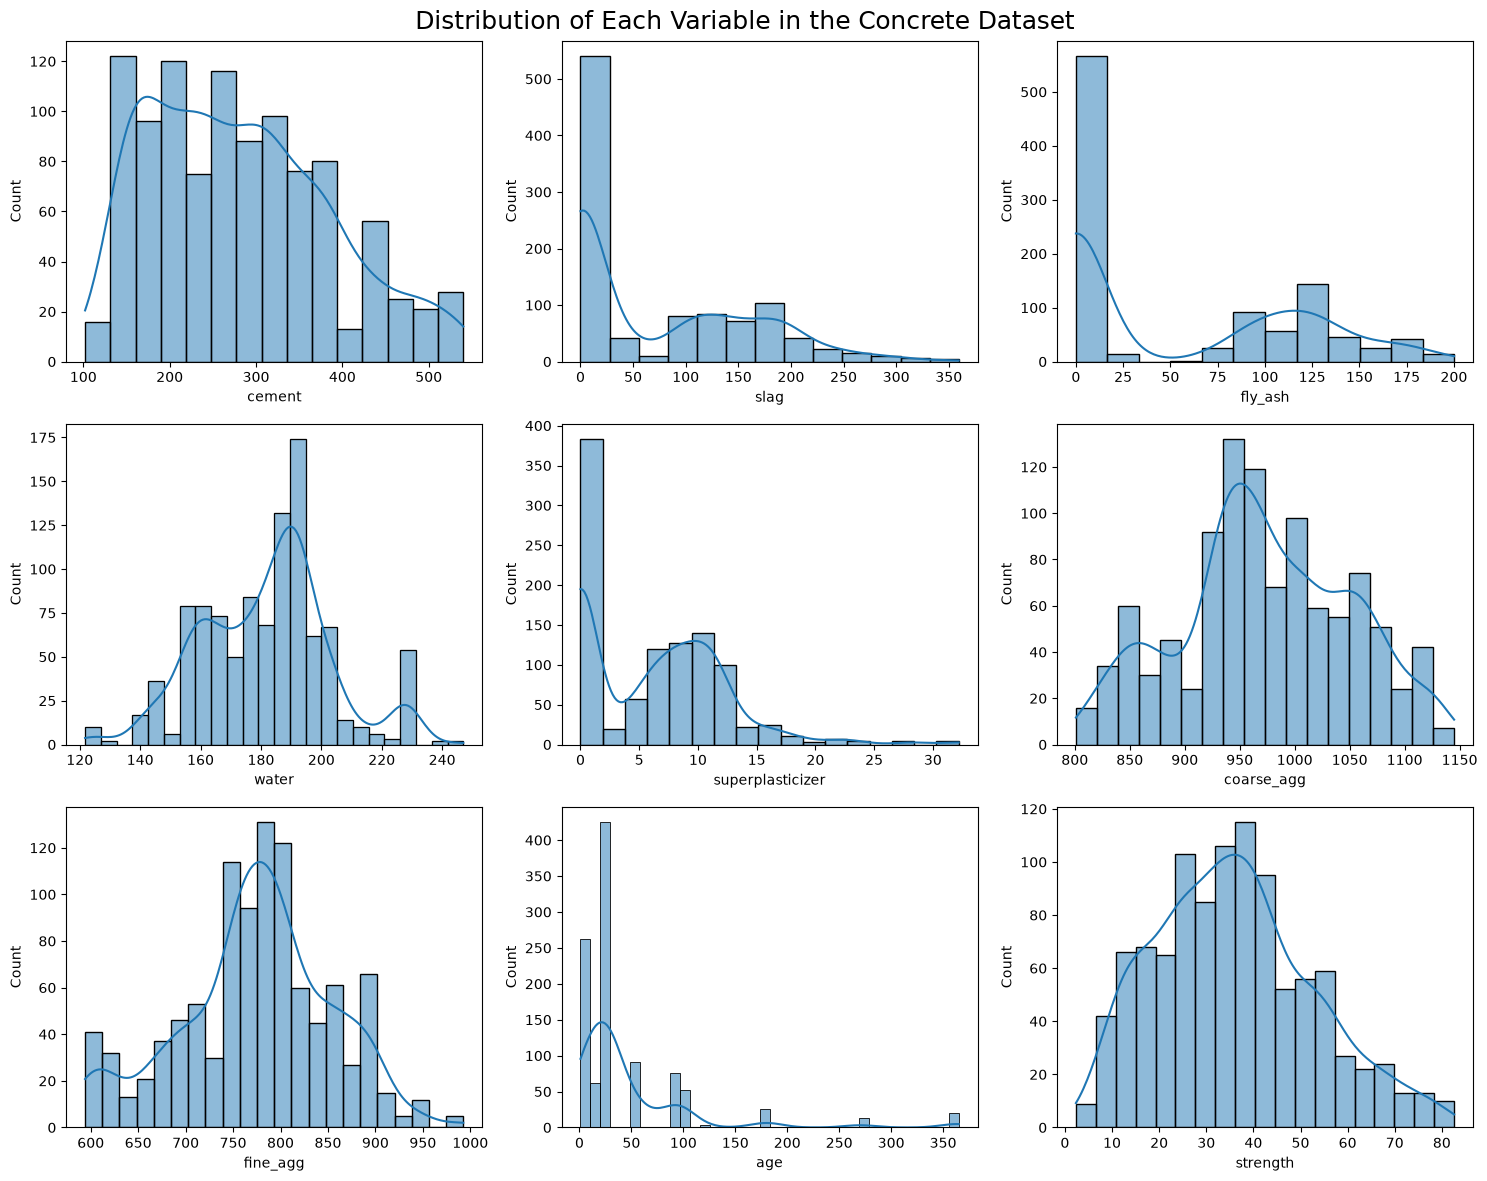

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle("Distribution of Each Variable in the Concrete Dataset", fontsize=18)

for ax, col in zip(axes.flat, df_clean_cols.columns):
    sns.histplot(data=df_clean_cols, x=col, kde=True, ax=ax)
    ax.set_xlabel(col.strip())
    ax.set_ylabel("Count")

fig.tight_layout()
plt.show()

In [16]:
import numpy as np

log_cols = ["age"]

df_clean_log = df_clean_cols.copy()
df_clean_log[log_cols] = np.log1p(df_clean_log[log_cols])

df_clean_log = df_clean_log.rename(columns={"age": "age_log"})


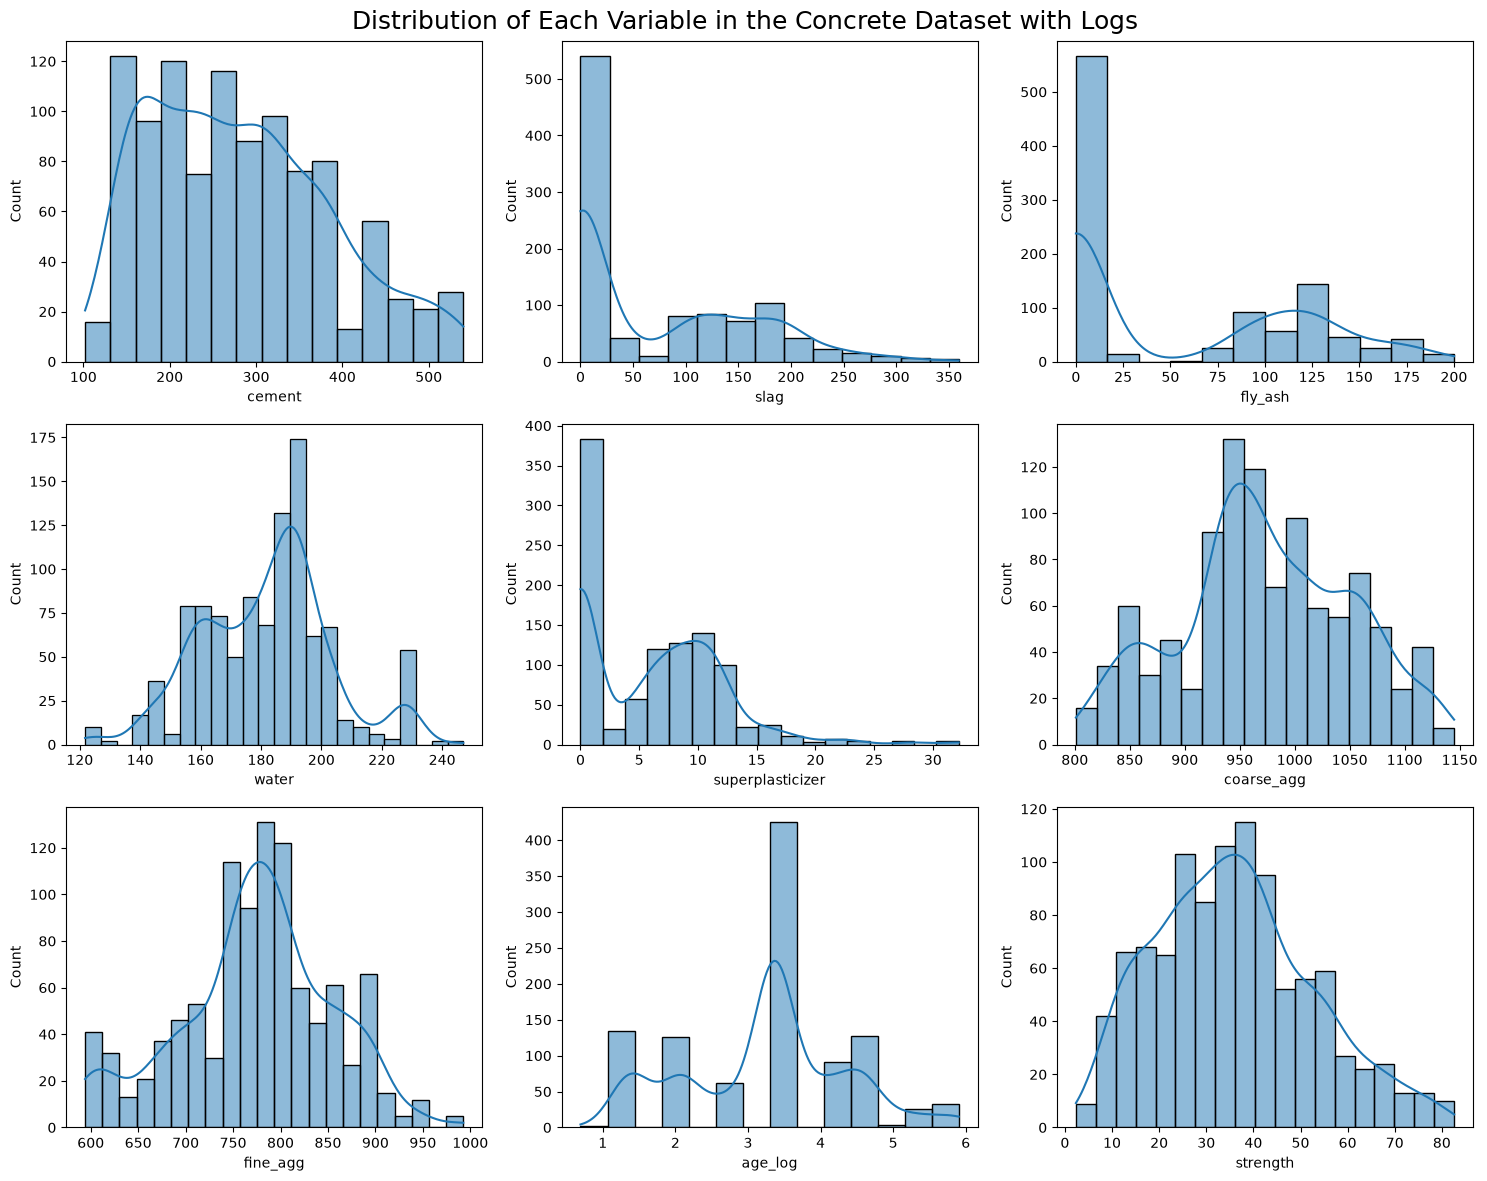

In [ ]:
# log of age because there is a heavy right skew
# not log of fly_ash or superplasticizer because those are just skewed by heavy 0 count which log does not help with 
# We can do log before split because model learns nothing from log

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle("Distribution of Each Variable in the Concrete Dataset with Logs", fontsize=18)

for ax, col in zip(axes.flat, df_clean_log.columns):
    sns.histplot(data=df_clean_log, x=col, kde=True, ax=ax)
    ax.set_xlabel(col.strip())
    ax.set_ylabel("Count")

fig.tight_layout()
plt.show()

Distribution looks normal for all variables except fly_ash or superplasticizer because those are just skewed by heavy 0 count which log does not help with. We can do log before split because model learns nothing from log. Variables will need to be standardized after split. 

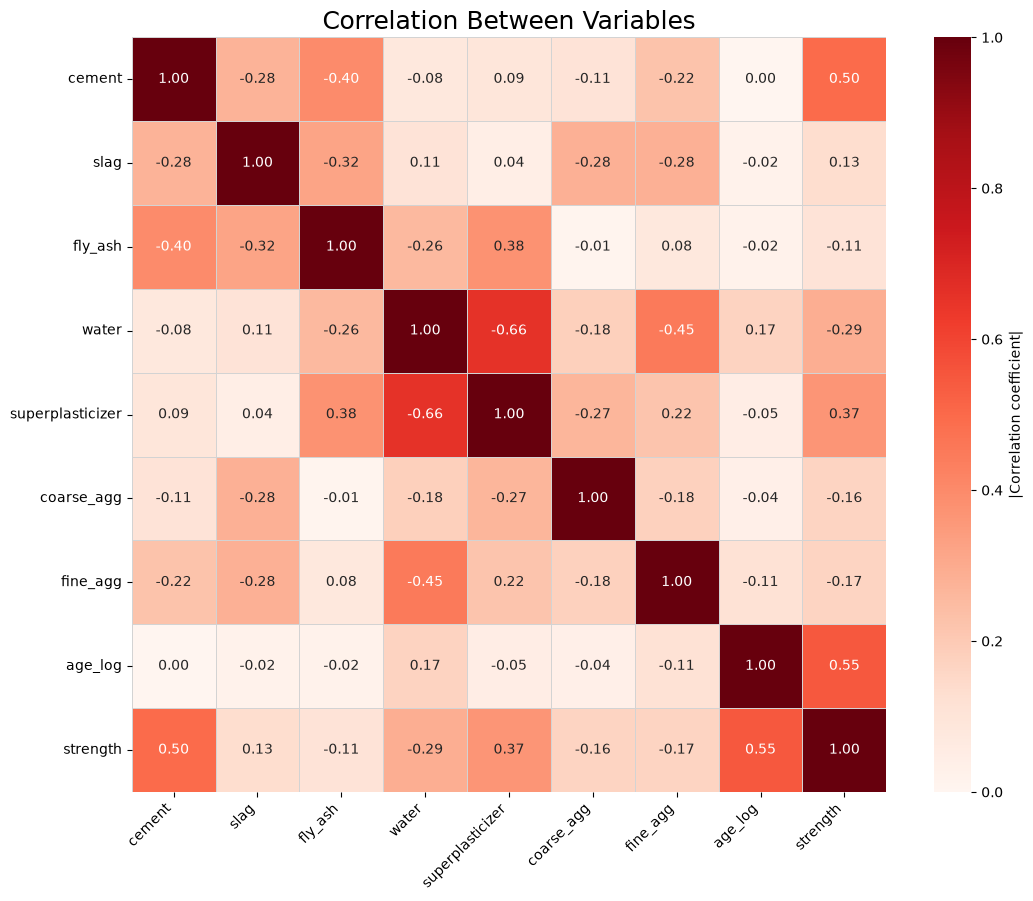

In [21]:
corr = df_clean_log.corr()
labels = [c.split("(")[0].strip() for c in corr.columns]  # shorten long names

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr.abs(), annot=corr, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
            square=True, linewidths=0.5, linecolor="lightgray",
            xticklabels=labels, yticklabels=labels,
            cbar_kws={"label": "|Correlation coefficient|"}, ax=ax)
ax.set_title("Correlation Between Variables", fontsize=18)
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
plt.show()

Since strength is the output, we should focus on the variable correlation with the strength variable. Cement and age_log have the highest corr_coeffs above 0.5, superplasticizer and water are close behind with corr_coeffs around 0.3, while the rest of the variables have significantly lower corr_coeffs of around 0.15.

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [4]:
# USE AS MANY CELLS AS NEEDED

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [5]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [6]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE